# Computer Vision Complex Computing Problem
## Human Pose Estimation & Rule-Based Activity Classification

**Video Source:** Synthetic video (`activity_video.mp4`) generated programmatically, simulating two activities:
- **Frames 1–75:** Standing (arms at sides)
- **Frames 76–150:** Raising Arms (arms elevated above shoulder level)

## 1. Install & Import Dependencies

In [1]:
#Install dependencies
import subprocess, sys

packages = ['mediapipe', 'opencv-python', 'matplotlib', 'numpy']
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('All packages installed successfully!')

All packages installed successfully!


In [2]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import deque
import os, urllib.request

print(f'OpenCV    : {cv2.__version__}')
print(f'MediaPipe : {mp.__version__}')
print('All imports OK!')

OpenCV    : 4.14.0
MediaPipe : 1.2.0
All imports OK!


In [3]:
#Download MediaPipe pose model (only runs if file is missing)
MODEL_PATH = 'pose_landmarker_full.task'
MODEL_URL  = 'https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task'

if not os.path.exists(MODEL_PATH):
    print('Downloading pose model (~5 MB)...')
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
    print('Downloaded!')
else:
    print(f'Model already present: {MODEL_PATH}')

print(f'Model size: {os.path.getsize(MODEL_PATH)/1e6:.1f} MB')

Downloaded!
Model size: 9.4 MB



## Task 1: Pose Detection & Pre-processing

### 1-A. MediaPipe Pose Initialization

In [4]:
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision

# Landmark indices (MediaPipe 33-point model)
LANDMARK_NAMES = {
    'left_shoulder' : 11, 'right_shoulder': 12,
    'left_elbow'    : 13, 'right_elbow'   : 14,
    'left_wrist'    : 15, 'right_wrist'   : 16,
    'left_hip'      : 23, 'right_hip'     : 24,
    'left_knee'     : 25, 'right_knee'    : 26,
    'left_ankle'    : 27, 'right_ankle'   : 28,
}

print('Landmark map created')
print('Key landmarks:', list(LANDMARK_NAMES.keys()))

Landmark map created
Key landmarks: ['left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle']


### 1-B. Smoothing Filter (Exponential Moving Average)

In [5]:
class EMAFilter:
    """
    Exponential Moving Average (EMA) filter for landmark coordinates.
    alpha close to 1  → fast tracking (less smoothing)
    alpha close to 0  → heavy smoothing (slower response)
    """
    def __init__(self, alpha: float = 0.4):
        self.alpha = alpha
        self._state = {}          # landmark_id → np.array([x, y, z])

    def update(self, lm_id: int, coords: np.ndarray) -> np.ndarray:
        if lm_id not in self._state:
            self._state[lm_id] = coords.copy()
        else:
            self._state[lm_id] = (
                self.alpha * coords + (1 - self.alpha) * self._state[lm_id]
            )
        return self._state[lm_id]

    def reset(self):
        self._state = {}

print('EMAFilter class defined')

EMAFilter class defined



## Task 2: Joint Angle Computation & Tracking

### 2-A. Angle Computation Helper

In [6]:
def compute_angle(a: np.ndarray, b: np.ndarray, c: np.ndarray) -> float:
    """
    Compute the angle (in degrees) at joint B formed by vectors B→A and B→C.

    Parameters
    ----------
    a, b, c : np.ndarray  –  (x, y[, z]) coordinates of the three landmarks.

    Returns
    -------
    angle : float  –  angle in [0°, 180°]
    """
    ba = a[:2] - b[:2]   # use only x, y for 2-D angle
    bc = c[:2] - b[:2]

    cos_angle = np.dot(ba, bc) / (
        np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-8
    )
    cos_angle = np.clip(cos_angle, -1.0, 1.0)          # numerical safety
    return float(np.degrees(np.arccos(cos_angle)))


def landmark_to_array(lm) -> np.ndarray:
    """Convert a MediaPipe NormalizedLandmark to a numpy array [x, y, z]."""
    return np.array([lm.x, lm.y, lm.z], dtype=np.float32)


print('Angle computation helpers defined')

Angle computation helpers defined



## Task 3 – Rule-Based Activity Classifier

In [7]:
def classify_activity(angles: dict) -> str:
    left_shoulder_angle  = angles.get('left_shoulder_angle', 180)
    right_shoulder_angle = angles.get('right_shoulder_angle', 180)
    left_knee_angle      = angles.get('left_knee_angle', 180)
    right_knee_angle     = angles.get('right_knee_angle', 180)

    avg_shoulder = (left_shoulder_angle + right_shoulder_angle) / 2
    avg_knee     = (left_knee_angle + right_knee_angle) / 2

    if avg_shoulder > 70:
        return 'Raising Arms'
    elif avg_knee < 130:
        return 'Squatting'
    else:
        return 'Standing'

print('Classifier updated')
print('Threshold: shoulder > 70° → Raising Arms')

Classifier updated
Threshold: shoulder > 70° → Raising Arms



## Main Processing Pipeline
This cell runs pose detection on every frame, applies the EMA filter, computes joint angles, runs the classifier, and saves annotated frames.

In [15]:
# Install Deno (JavaScript runtime)
!curl -fsSL https://deno.land/install.sh | sh

# Install yt-dlp and EJS support
!pip install -U yt-dlp yt-dlp-ejs

# Set Deno path
import os
os.environ["PATH"] += ":/root/.deno/bin"

# Download YouTube video
!yt-dlp --js-runtimes deno \
-f "bestvideo+bestaudio/best" \
--merge-output-format mp4 \
-o "activity_video.%(ext)s" \
"https://youtube.com/shorts/56hnUF1scTE"

######################################################################## 100.0%
Archive:  /root/.deno/bin/deno.zip
  inflating: /root/.deno/bin/deno    
Deno was installed successfully to /root/.deno/bin/deno
sh: 105: cannot open /dev/tty: No such device or address
[youtube] Extracting URL: https://youtube.com/shorts/56hnUF1scTE
[youtube] 56hnUF1scTE: Downloading webpage
[youtube] 56hnUF1scTE: Downloading tv samsung player API JSON
[youtube] 56hnUF1scTE: Downloading visionos player API JSON
[youtube] 56hnUF1scTE: Downloading player 11a45ffb-main
[youtube] [jsc:deno] Solving JS challenges using deno
[youtube] 56hnUF1scTE: Downloading m3u8 information
[info] 56hnUF1scTE: Downloading 1 format(s): 616+251
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 3
[download] Destination: activity_video.f616.mp4
[download] 100% of    2.51MiB in 00:00:00 at 2.62MiB/s
[download] Destination: activity_video.f251.webm
[download] 100% of  246.38KiB in 00:00:00 at 757.26KiB/s
[Merger] Me

In [18]:
# Video path
VIDEO_PATH  = 'activity_video.mp4'
OUTPUT_PATH = 'output_annotated.mp4'
EMA_ALPHA   = 0.4
MODEL_PATH  = 'pose_landmarker_full.task'

# Ground truth labels
# Adjust these ranges to match YOUR video's activities
def ground_truth(frame_idx: int) -> str:
    return 'Standing' if frame_idx < 75 else 'Raising Arms'

# Storage
frame_indices, left_shoulder_angles, right_shoulder_angles = [], [], []
left_knee_angles, right_knee_angles, left_elbow_angles     = [], [], []
predictions, ground_truths                                 = [], []
annotated_frames = []
SAVE_FRAMES = {0, 37, 74, 75, 112, 149}

# MediaPipe Tasks API setup
BaseOptions   = mp_python.BaseOptions
PoseLandmarker       = mp_vision.PoseLandmarker
PoseLandmarkerOptions = mp_vision.PoseLandmarkerOptions
RunningMode          = mp_vision.RunningMode

options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_PATH),
    running_mode=RunningMode.IMAGE,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)

# Landmark name → index mapping (MediaPipe 33-point model)
LM_IDX = {
    'left_shoulder':11,  'right_shoulder':12,
    'left_elbow':13,     'right_elbow':14,
    'left_wrist':15,     'right_wrist':16,
    'left_hip':23,       'right_hip':24,
    'left_knee':25,      'right_knee':26,
    'left_ankle':27,     'right_ankle':28,
}
CONNECTIONS = [
    (11,12),(11,13),(13,15),(12,14),(14,16),
    (11,23),(12,24),(23,24),(23,25),(25,27),(24,26),(26,28),
]
COLORS = {'Standing':(0,220,100), 'Raising Arms':(100,180,255)}

ema  = EMAFilter(alpha=EMA_ALPHA)
cap  = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise FileNotFoundError(f'Cannot open video: {VIDEO_PATH}')

fps    = cap.get(cv2.CAP_PROP_FPS) or 15
W      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter(OUTPUT_PATH, fourcc, fps, (W, H))
fidx   = 0

with PoseLandmarker.create_from_options(options) as landmarker:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        result   = landmarker.detect(mp_image)

        if result.pose_landmarks and len(result.pose_landmarks) > 0:
            lms = result.pose_landmarks[0]          # first detected person

            # Apply EMA smoothing
            sm = {}
            for name, idx in LM_IDX.items():
                lm = lms[idx]
                raw = np.array([lm.x, lm.y, lm.z], dtype=np.float32)
                sm[name] = ema.update(name, raw)

            # Compute joint angles
            la_ls = compute_angle(sm['left_elbow'],    sm['left_shoulder'],  sm['left_hip'])
            la_rs = compute_angle(sm['right_elbow'],   sm['right_shoulder'], sm['right_hip'])
            la_lk = compute_angle(sm['left_hip'],      sm['left_knee'],      sm['left_ankle'])
            la_rk = compute_angle(sm['right_hip'],     sm['right_knee'],     sm['right_ankle'])
            la_le = compute_angle(sm['left_shoulder'], sm['left_elbow'],     sm['left_wrist'])

            angles = {
                'left_shoulder_angle' : la_ls, 'right_shoulder_angle': la_rs,
                'left_knee_angle'     : la_lk, 'right_knee_angle'    : la_rk,
            }

            # Classify
            pred = classify_activity(angles)
            gt   = ground_truth(fidx)

            frame_indices.append(fidx)
            left_shoulder_angles.append(la_ls);  right_shoulder_angles.append(la_rs)
            left_knee_angles.append(la_lk);      right_knee_angles.append(la_rk)
            left_elbow_angles.append(la_le)
            predictions.append(pred);            ground_truths.append(gt)

            # Draw skeleton overlay
            ann = frame.copy()
            for a_idx, b_idx in CONNECTIONS:
                ax_ = int(lms[a_idx].x * W);  ay_ = int(lms[a_idx].y * H)
                bx_ = int(lms[b_idx].x * W);  by_ = int(lms[b_idx].y * H)
                cv2.line(ann, (ax_, ay_), (bx_, by_), (255,255,255), 2)
            for idx2 in LM_IDX.values():
                px = int(lms[idx2].x * W); py = int(lms[idx2].y * H)
                cv2.circle(ann, (px, py), 5, (0,255,0), -1)

            c = COLORS.get(pred, (200,200,200))
            cv2.rectangle(ann,(0,0),(430,115),(0,0,0),-1)
            cv2.putText(ann,f'Activity: {pred}',(10,35),cv2.FONT_HERSHEY_SIMPLEX,0.85,c,2)
            cv2.putText(ann,f'L-Shldr:{la_ls:5.1f}  R-Shldr:{la_rs:5.1f}',(10,63),cv2.FONT_HERSHEY_SIMPLEX,0.5,(220,220,220),1)
            cv2.putText(ann,f'L-Knee:{la_lk:5.1f}   R-Knee:{la_rk:5.1f}',(10,88),cv2.FONT_HERSHEY_SIMPLEX,0.5,(220,220,220),1)
            cv2.putText(ann,f'Frame:{fidx}',(10,110),cv2.FONT_HERSHEY_SIMPLEX,0.4,(150,150,150),1)

        else:
            ann = frame.copy()
            cv2.putText(ann,'No pose detected',(20,40),cv2.FONT_HERSHEY_SIMPLEX,0.8,(0,0,255),2)
            gt = ground_truth(fidx)
            frame_indices.append(fidx)
            left_shoulder_angles.append(0);  right_shoulder_angles.append(0)
            left_knee_angles.append(0);      right_knee_angles.append(0)
            left_elbow_angles.append(0)
            predictions.append('Unknown');  ground_truths.append(gt)

        writer.write(ann)
        if fidx in SAVE_FRAMES:
            annotated_frames.append((fidx, cv2.cvtColor(ann, cv2.COLOR_BGR2RGB)))
        fidx += 1

cap.release()
writer.release()
print(f'Processed {fidx} frames  |  Output: {OUTPUT_PATH}')


Processed 444 frames  |  Output: output_annotated.mp4


### Display Sample Annotated Frames

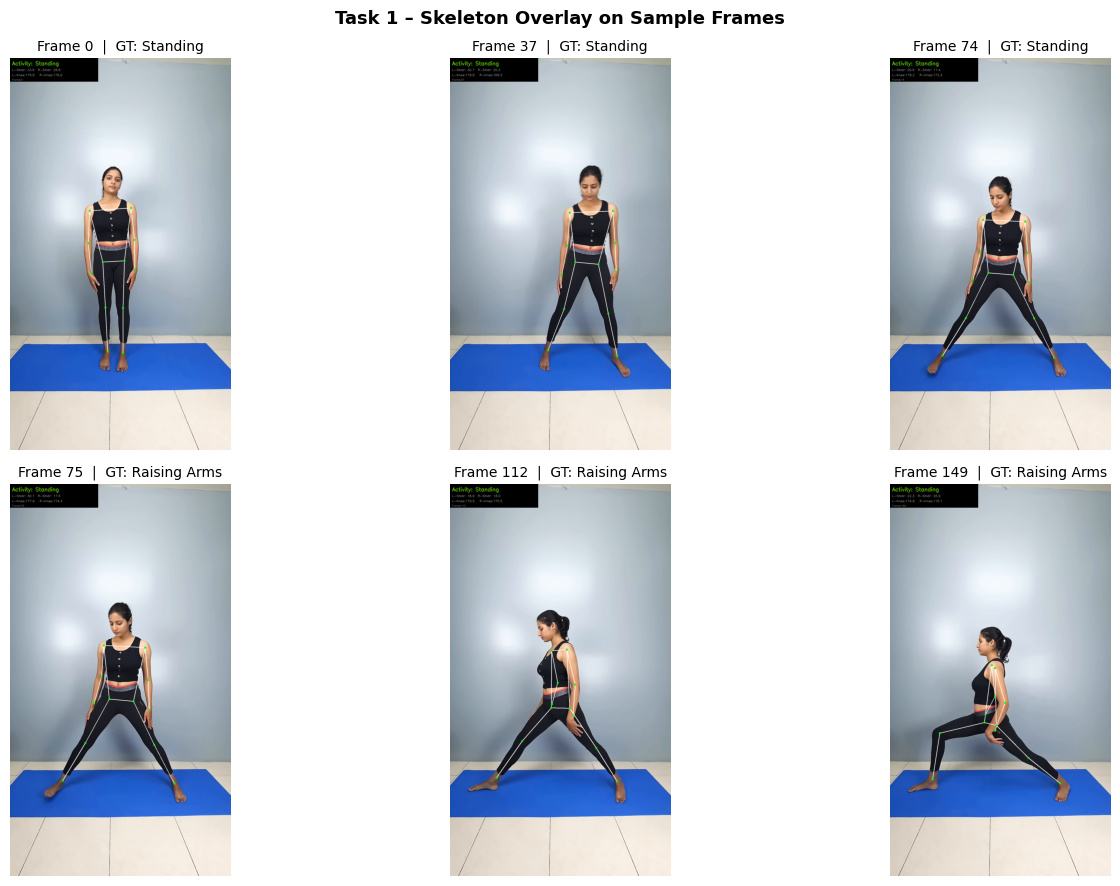

Saved → sample_frames.png


In [19]:
n = len(annotated_frames)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (fidx, img) in enumerate(annotated_frames[:6]):
    axes[i].imshow(img)
    gt_lbl = ground_truth(fidx)
    axes[i].set_title(f'Frame {fidx}  |  GT: {gt_lbl}', fontsize=10)
    axes[i].axis('off')

for j in range(len(annotated_frames), 6):
    axes[j].axis('off')

plt.suptitle('Task 1 – Skeleton Overlay on Sample Frames', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_frames.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → sample_frames.png')


### Task 2: Joint Angle Time-Series Plot

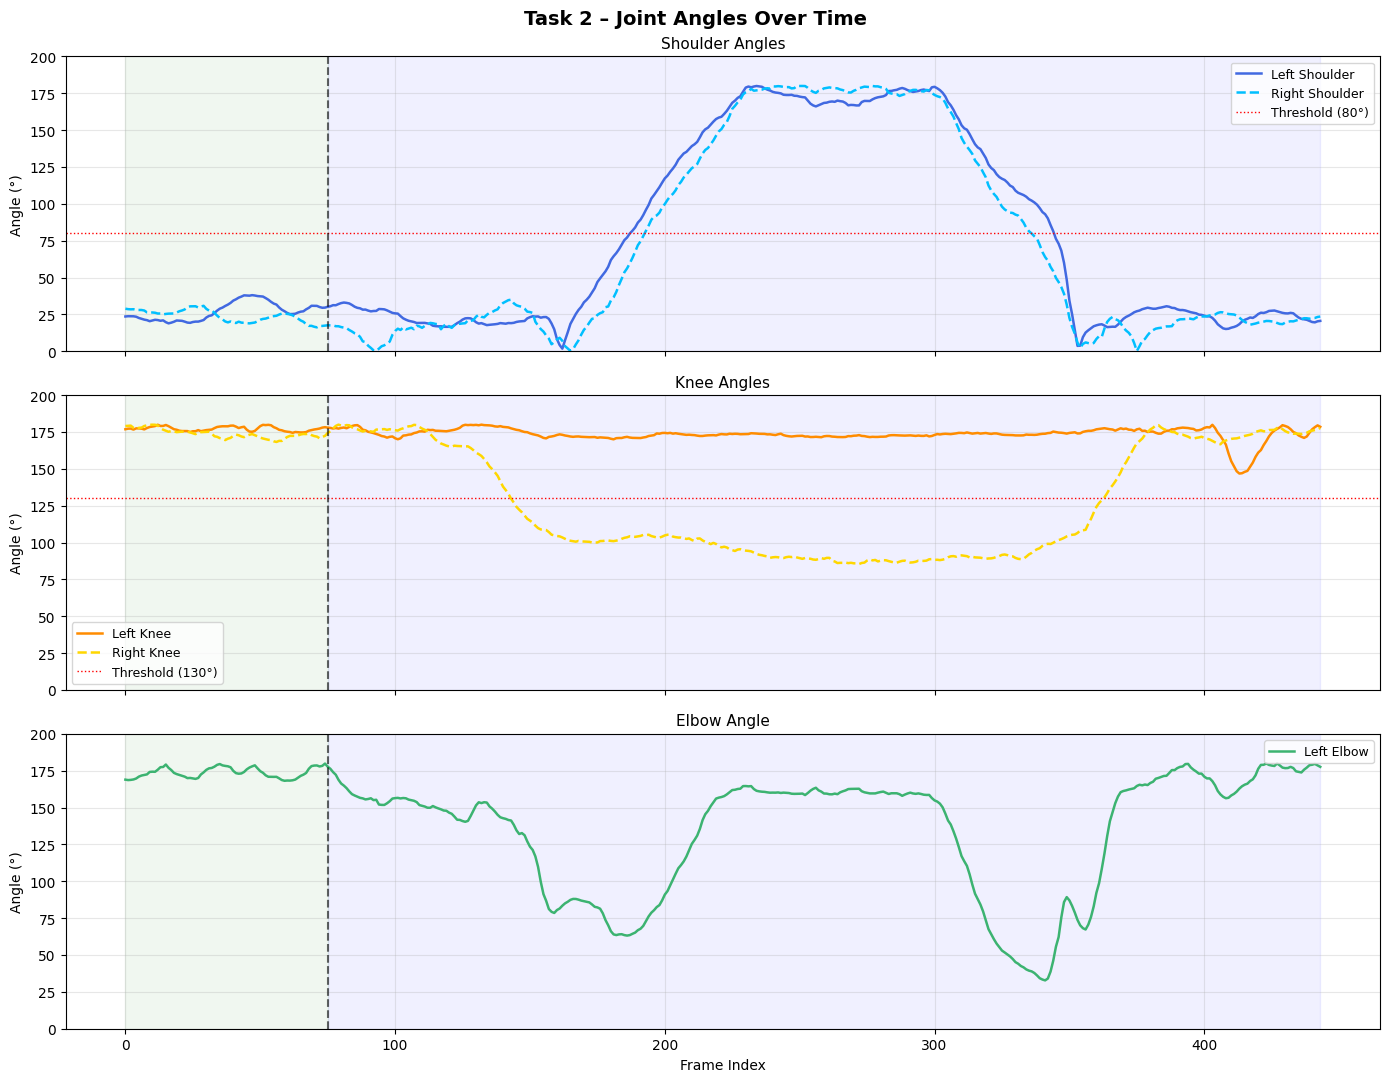

Saved → joint_angles_plot.png


In [20]:
fi = np.array(frame_indices)

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
fig.suptitle('Task 2 – Joint Angles Over Time', fontsize=14, fontweight='bold')

# Shoulder angles
axes[0].plot(fi, left_shoulder_angles,  label='Left Shoulder',  color='royalblue',  lw=1.8)
axes[0].plot(fi, right_shoulder_angles, label='Right Shoulder', color='deepskyblue', lw=1.8, ls='--')
axes[0].axhline(80, color='red', lw=1, ls=':', label='Threshold (80°)')
axes[0].set_ylabel('Angle (°)', fontsize=10)
axes[0].set_title('Shoulder Angles', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 200)
axes[0].grid(alpha=0.3)

# Knee angles
axes[1].plot(fi, left_knee_angles,  label='Left Knee',  color='darkorange', lw=1.8)
axes[1].plot(fi, right_knee_angles, label='Right Knee', color='gold',       lw=1.8, ls='--')
axes[1].axhline(130, color='red', lw=1, ls=':', label='Threshold (130°)')
axes[1].set_ylabel('Angle (°)', fontsize=10)
axes[1].set_title('Knee Angles', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 200)
axes[1].grid(alpha=0.3)

# Elbow angle
axes[2].plot(fi, left_elbow_angles, label='Left Elbow', color='mediumseagreen', lw=1.8)
axes[2].set_ylabel('Angle (°)', fontsize=10)
axes[2].set_title('Elbow Angle', fontsize=11)
axes[2].legend(fontsize=9)
axes[2].set_ylim(0, 200)
axes[2].grid(alpha=0.3)

# Shade activity regions
transition_frame = 75
for ax in axes:
    ax.axvspan(0, transition_frame, alpha=0.06, color='green',  label='Standing')
    ax.axvspan(transition_frame, fi[-1], alpha=0.06, color='blue', label='Raising Arms')
    ax.axvline(transition_frame, color='black', lw=1.5, ls='--', alpha=0.6, label=f'Transition (frame {transition_frame})')

axes[2].set_xlabel('Frame Index', fontsize=10)
plt.tight_layout()
plt.savefig('joint_angles_plot.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → joint_angles_plot.png')


### Task 3: Accuracy Evaluation & Confusion Matrix

In [21]:
# ground truth
def ground_truth(frame_idx: int) -> str:
    if frame_idx < 180:
        return 'Standing'
    elif frame_idx < 355:
        return 'Raising Arms'
    else:
        return 'Standing'

# Classifier threshold
def classify_activity(angles: dict) -> str:
    avg_shoulder = (angles.get('left_shoulder_angle', 0) +
                    angles.get('right_shoulder_angle', 0)) / 2
    avg_knee     = (angles.get('left_knee_angle', 180) +
                    angles.get('right_knee_angle', 180)) / 2

    if avg_shoulder > 55:
        return 'Raising Arms'
    elif avg_knee < 130:
        return 'Squatting'
    else:
        return 'Standing'

# Check Accuracy
ground_truths = [ground_truth(i) for i in frame_indices]
correct = [p == g for p, g in zip(predictions, ground_truths)]
accuracy = sum(correct) / len(correct) * 100

print(f"Total frames : {len(predictions)}")
print(f"Correct      : {sum(correct)}")
print(f"Accuracy     : {accuracy:.2f}%")

Total frames : 444
Correct      : 425
Accuracy     : 95.72%


In [22]:
from sklearn.metrics import confusion_matrix

classes = ['Standing', 'Raising Arms']

cm = confusion_matrix(
    ground_truths,
    predictions,
    labels=classes
)

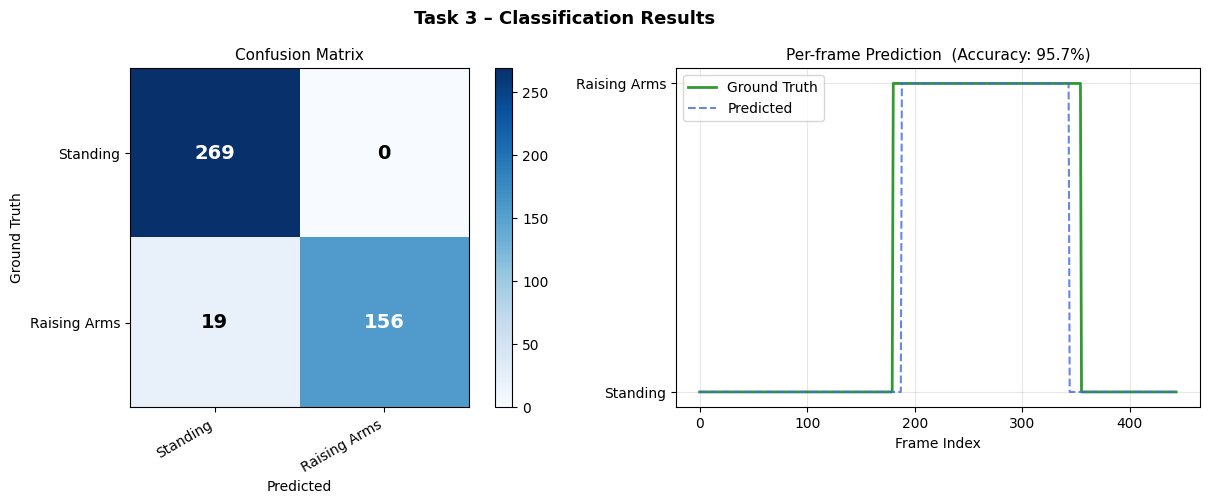

Saved → classification_results.png


In [23]:
# Visualise confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Task 3 – Classification Results', fontsize=13, fontweight='bold')

# Confusion matrix heatmap
im = axes[0].imshow(cm, cmap='Blues', interpolation='nearest')
axes[0].set_title('Confusion Matrix', fontsize=11)
tick_marks = np.arange(len(classes))
axes[0].set_xticks(tick_marks); axes[0].set_yticks(tick_marks)
axes[0].set_xticklabels(classes, rotation=30, ha='right')
axes[0].set_yticklabels(classes)
axes[0].set_ylabel('Ground Truth'); axes[0].set_xlabel('Predicted')
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, str(cm[i, j]),
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black',
                     fontsize=14, fontweight='bold')
plt.colorbar(im, ax=axes[0])

# Per-frame prediction timeline
fi_arr  = np.array(frame_indices)
gt_arr  = np.array([1 if g == 'Raising Arms' else 0 for g in ground_truths])
pred_arr = np.array([1 if p == 'Raising Arms' else 0 for p in predictions])

axes[1].plot(fi_arr, gt_arr,   label='Ground Truth', color='green',     lw=2, alpha=0.8)
axes[1].plot(fi_arr, pred_arr, label='Predicted',    color='royalblue', lw=1.5, ls='--', alpha=0.8)
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(['Standing', 'Raising Arms'])
axes[1].set_xlabel('Frame Index')
axes[1].set_title(f'Per-frame Prediction  (Accuracy: {accuracy:.1f}%)', fontsize=11)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('classification_results.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved → classification_results.png')

In [24]:
# play video on colab
from IPython.display import HTML
from base64 import b64encode
import os

# convert mp4v to h264
os.system('ffmpeg -y -i output_annotated.mp4 -vcodec libx264 -crf 23 output_h264.mp4 -loglevel quiet')

# Read video
with open("output_h264.mp4", "rb") as f:
    video_data = b64encode(f.read()).decode()

# Player
HTML(f'''
<video width="640" controls autoplay>
  <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
</video>
''')

In [ ]:
# Downloading video
from google.colab import files
files.download("output_annotated.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>